# 📸 Pizarra Snap

## Sistema inteligente de captura de pizarras mediante visión por computadora

### Objetivo

Desarrollar un sistema capaz de detectar acciones visuales realizadas por un docente sobre una pizarra para generar capturas automáticas sin utilizar comandos de voz, teclado, mouse ni botones electrónicos.

El sistema reconocerá tres tipos de eventos:

- 📸 Captura normal
- ⭐ Concepto importante
- 📌 Fin de tema

Luego de detectar un evento, analizará una breve secuencia de frames posteriores para seleccionar automáticamente la imagen de mejor calidad.

---

## Etapa 1 — Video y frames

En esta primera etapa voy a:

1. cargar el video de prueba;
2. abrirlo con OpenCV;
3. obtener sus características;
4. comprender cómo un video está formado por una secuencia de frames;
5. extraer y visualizar algunos frames.

In [1]:
# Importo OpenCV para trabajar con videos e imágenes.
import cv2

# Importo NumPy para trabajar con los frames como matrices de píxeles.
import numpy as np

# Importo Matplotlib para visualizar imágenes y resultados.
import matplotlib.pyplot as plt

# Importo herramientas de Colab para poder cargar archivos desde la computadora.
from google.colab import files

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [2]:
# Abro el selector de archivos para cargar el video desde mi computadora.
archivos_subidos = files.upload()

# Obtengo automáticamente el nombre del archivo que acabo de subir.
nombre_video = list(archivos_subidos.keys())[0]

# Muestro el nombre para comprobar que el archivo se cargó correctamente.
print("Video cargado:", nombre_video)

Saving proyecto_pizzarasnap.mp4 to proyecto_pizzarasnap.mp4
Video cargado: proyecto_pizzarasnap.mp4


In [3]:
# Abro el video con OpenCV usando el nombre del archivo que cargué.
video = cv2.VideoCapture(nombre_video)

# Verifico que OpenCV haya podido abrir correctamente el video.
if video.isOpened():
    print("Video abierto correctamente.")
else:
    print("Error: no se pudo abrir el video.")

Video abierto correctamente.


In [4]:
# Obtengo la cantidad de frames que contiene el video.
total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

# Obtengo la cantidad de frames por segundo.
fps = video.get(cv2.CAP_PROP_FPS)

# Obtengo el ancho del video en píxeles.
ancho = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))

# Obtengo el alto del video en píxeles.
alto = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Calculo la duración aproximada del video en segundos.
duracion = total_frames / fps

# Muestro los datos principales del video.
print("Resolución:", ancho, "x", alto)
print("FPS:", fps)
print("Cantidad de frames:", total_frames)
print("Duración aproximada:", round(duracion, 2), "segundos")

Resolución: 1920 x 1080
FPS: 28.843967150979154
Cantidad de frames: 1522
Duración aproximada: 52.77 segundos


In [5]:
# Coloco el video nuevamente al comienzo para asegurarme de leer el primer frame.
video.set(cv2.CAP_PROP_POS_FRAMES, 0)

# Leo el primer frame del video.
# "leido" indica si OpenCV pudo leerlo correctamente.
# "frame" contiene la imagen obtenida.
leido, frame = video.read()

# Verifico que el primer frame se haya leído correctamente.
if leido:
    print("Primer frame leído correctamente.")
else:
    print("Error: no se pudo leer el primer frame.")

Primer frame leído correctamente.


In [6]:
# Muestro el tipo de dato almacenado en la variable frame.
print("Tipo de frame:", type(frame))

# Muestro la forma o dimensiones de la imagen.
print("Shape del frame:", frame.shape)

# Muestro el tipo de dato utilizado para almacenar cada valor de píxel.
print("Tipo de dato de los píxeles:", frame.dtype)

Tipo de frame: <class 'numpy.ndarray'>
Shape del frame: (1080, 1920, 3)
Tipo de dato de los píxeles: uint8


In [ ]:
# Convierto el frame de BGR a RGB para mostrar correctamente los colores con Matplotlib.
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

# Creo una figura para visualizar la imagen.
plt.figure(figsize=(14, 8))

# Muestro el primer frame.
plt.imshow(frame_rgb)

# Agrego un título descriptivo.
plt.title("Primer frame del video - Pizarra Snap")

# Oculto los números de los ejes porque ahora me interesa observar la imagen.
plt.axis("off")

# Muestro el resultado.
plt.show()

In [8]:
# Elijo un píxel aproximadamente en el centro de la imagen.
fila = 540
columna = 960

# Obtengo los valores de color de ese píxel.
pixel = frame[fila, columna]

# Muestro el resultado.
print("Píxel seleccionado:", pixel)
print("Canal Azul (B):", pixel[0])
print("Canal Verde (G):", pixel[1])
print("Canal Rojo (R):", pixel[2])

Píxel seleccionado: [142 144 126]
Canal Azul (B): 142
Canal Verde (G): 144
Canal Rojo (R): 126


In [ ]:
# Convierto el frame de BGR a RGB para visualizar correctamente los colores.
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

# Creo una figura grande para observar bien las coordenadas.
plt.figure(figsize=(16, 9))

# Muestro el frame completo.
plt.imshow(frame_rgb)

# Agrego un título.
plt.title("Frame con coordenadas - Pizarra Snap")

# Mantengo visibles los ejes para identificar posiciones dentro de la imagen.
plt.xlabel("Coordenada X - ancho")
plt.ylabel("Coordenada Y - alto")

# Muestro una grilla para facilitar la ubicación de las zonas.
plt.grid()

plt.show()

In [10]:
# Defino las coordenadas corregidas de las tres regiones de interés (ROI).
# Ajusto cada región para que encierre solamente su símbolo correspondiente.

# ROI 1 - Captura normal
x1_normal, x2_normal = 75, 210
y1_normal, y2_normal = 190, 300

# ROI 2 - Concepto importante
x1_importante, x2_importante = 75, 210
y1_importante, y2_importante = 400, 510

# ROI 3 - Fin de tema
x1_fin, x2_fin = 75, 215
y1_fin, y2_fin = 585, 740

print("Coordenadas corregidas de las ROI definidas correctamente.")

Coordenadas corregidas de las ROI definidas correctamente.


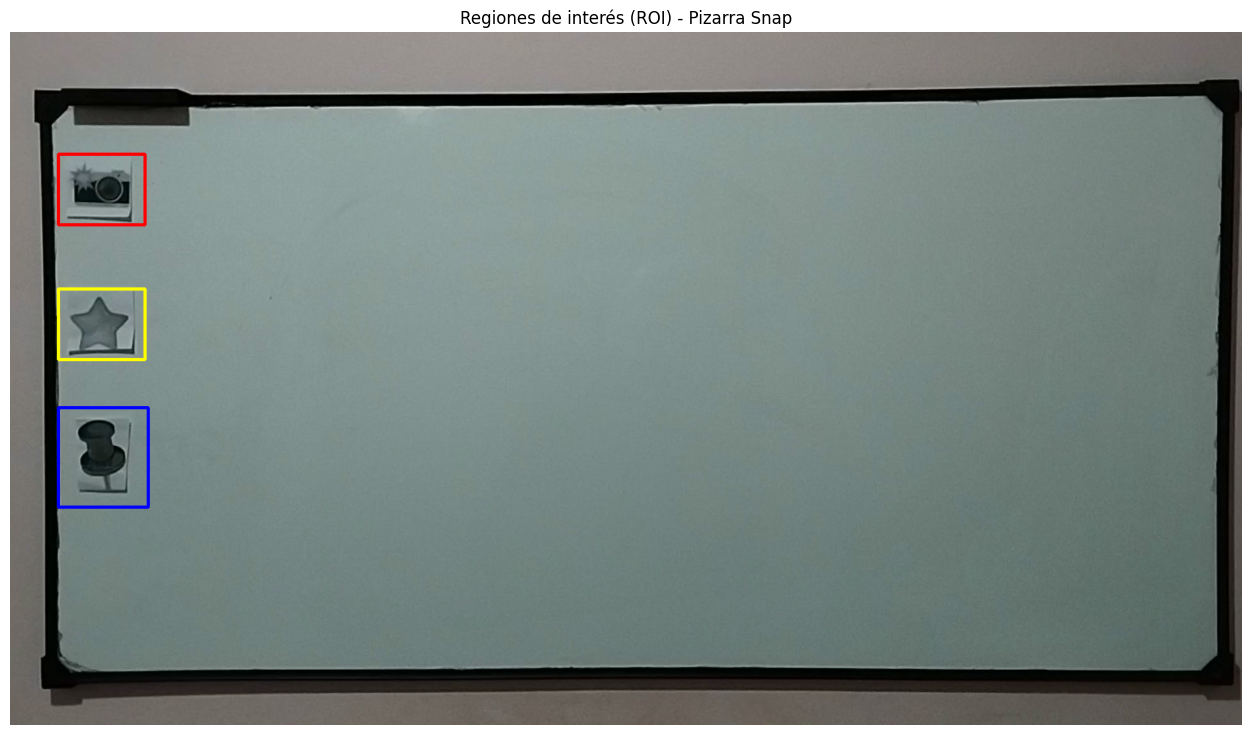

In [11]:
# Creo una copia del frame para dibujar las ROI sin modificar la imagen original.
frame_roi = frame.copy()

# Dibujo la ROI de Captura normal.
cv2.rectangle(
    frame_roi,
    (x1_normal, y1_normal),
    (x2_normal, y2_normal),
    (0, 0, 255),
    3
)

# Dibujo la ROI de Concepto importante.
cv2.rectangle(
    frame_roi,
    (x1_importante, y1_importante),
    (x2_importante, y2_importante),
    (0, 255, 255),
    3
)

# Dibujo la ROI de Fin de tema.
cv2.rectangle(
    frame_roi,
    (x1_fin, y1_fin),
    (x2_fin, y2_fin),
    (255, 0, 0),
    3
)

# Convierto de BGR a RGB para visualizar correctamente con Matplotlib.
frame_roi_rgb = cv2.cvtColor(frame_roi, cv2.COLOR_BGR2RGB)

# Muestro el frame completo con las tres regiones marcadas.
plt.figure(figsize=(16, 9))
plt.imshow(frame_roi_rgb)
plt.title("Regiones de interés (ROI) - Pizarra Snap")
plt.axis("off")
plt.show()

In [12]:
# Recorto las tres regiones de interés directamente desde la matriz del frame.
# Uso slicing de NumPy con la forma: frame[y1:y2, x1:x2].

# ROI 1 - Captura normal
roi_normal = frame[y1_normal:y2_normal, x1_normal:x2_normal]

# ROI 2 - Concepto importante
roi_importante = frame[
    y1_importante:y2_importante,
    x1_importante:x2_importante
]

# ROI 3 - Fin de tema
roi_fin = frame[y1_fin:y2_fin, x1_fin:x2_fin]

# Muestro las dimensiones de cada ROI.
print("Shape ROI Normal:", roi_normal.shape)
print("Shape ROI Importante:", roi_importante.shape)
print("Shape ROI Fin de tema:", roi_fin.shape)

Shape ROI Normal: (110, 135, 3)
Shape ROI Importante: (110, 135, 3)
Shape ROI Fin de tema: (155, 140, 3)


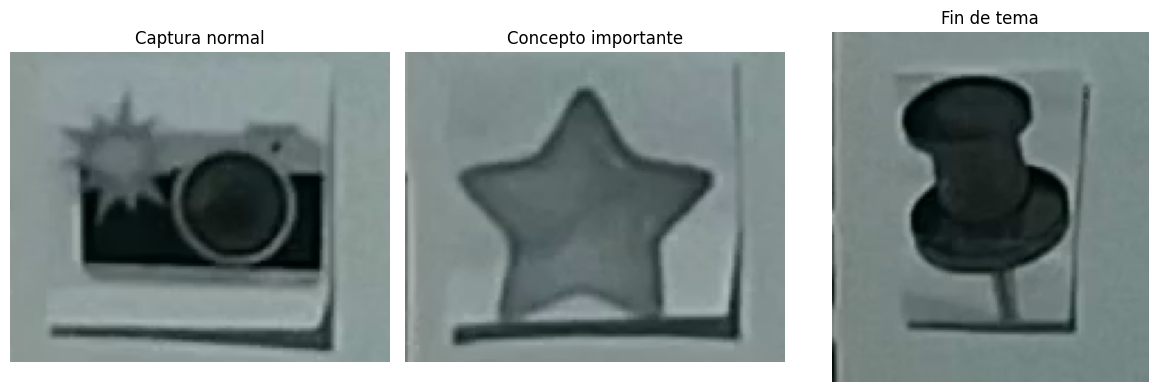

In [13]:
# Convierto cada ROI de BGR a RGB para visualizar correctamente con Matplotlib.
roi_normal_rgb = cv2.cvtColor(roi_normal, cv2.COLOR_BGR2RGB)
roi_importante_rgb = cv2.cvtColor(roi_importante, cv2.COLOR_BGR2RGB)
roi_fin_rgb = cv2.cvtColor(roi_fin, cv2.COLOR_BGR2RGB)

# Creo una figura para visualizar las tres regiones juntas.
plt.figure(figsize=(12, 4))

# Muestro la ROI de Captura normal.
plt.subplot(1, 3, 1)
plt.imshow(roi_normal_rgb)
plt.title("Captura normal")
plt.axis("off")

# Muestro la ROI de Concepto importante.
plt.subplot(1, 3, 2)
plt.imshow(roi_importante_rgb)
plt.title("Concepto importante")
plt.axis("off")

# Muestro la ROI de Fin de tema.
plt.subplot(1, 3, 3)
plt.imshow(roi_fin_rgb)
plt.title("Fin de tema")
plt.axis("off")

# Ajusto automáticamente los espacios entre las imágenes.
plt.tight_layout()

# Muestro el resultado.
plt.show()

## 📊 RF04 — Análisis de histogramas

En esta etapa se preparan las tres regiones de interés (ROI) para obtener una representación numérica de su contenido visual.

El procesamiento utilizado será:

```text
ROI original
     ↓
Escala de grises
     ↓
Gaussian Blur
     ↓
Histograma
     ↓
Normalización

In [14]:
# Convierto las tres regiones de interés de BGR a escala de grises.
# De esta manera cada píxel queda representado por un único valor de intensidad.

roi_normal_gris = cv2.cvtColor(roi_normal, cv2.COLOR_BGR2GRAY)
roi_importante_gris = cv2.cvtColor(roi_importante, cv2.COLOR_BGR2GRAY)
roi_fin_gris = cv2.cvtColor(roi_fin, cv2.COLOR_BGR2GRAY)

# Reviso las dimensiones obtenidas para comprobar que desapareció el canal de color.
print("Shape ROI Normal en gris:", roi_normal_gris.shape)
print("Shape ROI Importante en gris:", roi_importante_gris.shape)
print("Shape ROI Fin de tema en gris:", roi_fin_gris.shape)

Shape ROI Normal en gris: (110, 135)
Shape ROI Importante en gris: (110, 135)
Shape ROI Fin de tema en gris: (155, 140)


In [15]:
# Aplico un suavizado Gaussiano a las tres ROI en escala de grises.
# Uso un kernel de 5x5 para reducir pequeñas variaciones y ruido de la imagen.

roi_normal_suavizada = cv2.GaussianBlur(
    roi_normal_gris,
    (5, 5),
    0
)

roi_importante_suavizada = cv2.GaussianBlur(
    roi_importante_gris,
    (5, 5),
    0
)

roi_fin_suavizada = cv2.GaussianBlur(
    roi_fin_gris,
    (5, 5),
    0
)

# Compruebo que el suavizado mantiene las mismas dimensiones de cada ROI.

print("Shape ROI Normal suavizada:", roi_normal_suavizada.shape)
print("Shape ROI Importante suavizada:", roi_importante_suavizada.shape)
print("Shape ROI Fin de tema suavizada:", roi_fin_suavizada.shape)

Shape ROI Normal suavizada: (110, 135)
Shape ROI Importante suavizada: (110, 135)
Shape ROI Fin de tema suavizada: (155, 140)


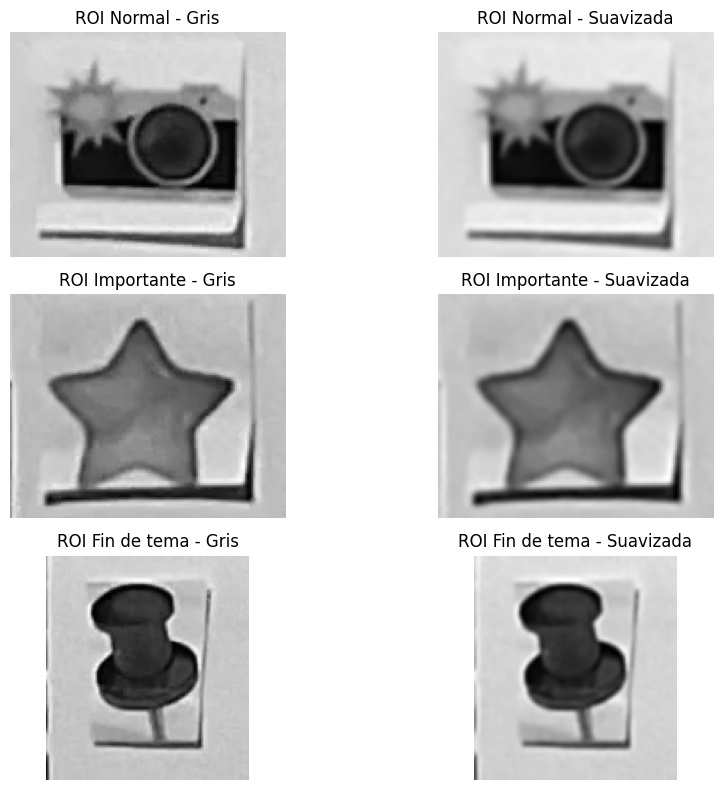

In [16]:
# Comparo visualmente cada ROI en escala de grises con su versión suavizada.
# Esto permite observar el efecto real del Gaussian Blur.

plt.figure(figsize=(10, 8))

# ROI Captura normal
plt.subplot(3, 2, 1)
plt.imshow(roi_normal_gris, cmap="gray")
plt.title("ROI Normal - Gris")
plt.axis("off")

plt.subplot(3, 2, 2)
plt.imshow(roi_normal_suavizada, cmap="gray")
plt.title("ROI Normal - Suavizada")
plt.axis("off")

# ROI Concepto importante
plt.subplot(3, 2, 3)
plt.imshow(roi_importante_gris, cmap="gray")
plt.title("ROI Importante - Gris")
plt.axis("off")

plt.subplot(3, 2, 4)
plt.imshow(roi_importante_suavizada, cmap="gray")
plt.title("ROI Importante - Suavizada")
plt.axis("off")

# ROI Fin de tema
plt.subplot(3, 2, 5)
plt.imshow(roi_fin_gris, cmap="gray")
plt.title("ROI Fin de tema - Gris")
plt.axis("off")

plt.subplot(3, 2, 6)
plt.imshow(roi_fin_suavizada, cmap="gray")
plt.title("ROI Fin de tema - Suavizada")
plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
# Calculo el histograma de cada ROI suavizada.
# Como las imágenes están en escala de grises, analizo un solo canal.
# Utilizo 256 posiciones porque los píxeles pueden tener valores entre 0 y 255.

hist_normal = cv2.calcHist(
    [roi_normal_suavizada],
    [0],
    None,
    [256],
    [0, 256]
)

hist_importante = cv2.calcHist(
    [roi_importante_suavizada],
    [0],
    None,
    [256],
    [0, 256]
)

hist_fin = cv2.calcHist(
    [roi_fin_suavizada],
    [0],
    None,
    [256],
    [0, 256]
)

# Reviso la forma de los histogramas obtenidos.

print("Shape histograma Normal:", hist_normal.shape)
print("Shape histograma Importante:", hist_importante.shape)
print("Shape histograma Fin de tema:", hist_fin.shape)

Shape histograma Normal: (256,)
Shape histograma Importante: (256,)
Shape histograma Fin de tema: (256,)


### 📈 ¿Cómo se interpreta un histograma?

En este paso se visualizan los histogramas correspondientes a las tres regiones de interés:

- 📸 Captura normal
- ⭐ Concepto importante
- 📌 Fin de tema

Un **histograma** resume cómo se distribuyen las intensidades de los píxeles dentro de una imagen.

Como previamente convertimos las ROI a **escala de grises**, cada píxel posee un único valor comprendido entre `0` y `255`:

```text
0 ---------------------------------------- 255
negro                                     blanco
```

En el gráfico:

- el **eje horizontal (X)** representa la intensidad del píxel;
- el **eje vertical (Y)** representa cuántos píxeles poseen esa intensidad.

Por ejemplo, si aparece un pico alto cerca de la intensidad `150`, significa que dentro de esa ROI existen muchos píxeles con un tono de gris cercano a `150`.

Los picos permiten observar qué intensidades predominan dentro de cada región.

Podemos pensar el proceso así:

```text
Imagen de la ROI
       ↓
Valores de sus píxeles
       ↓
Histograma
       ↓
Resumen de la distribución de intensidades
```

El histograma no conserva la posición exacta de cada píxel. En cambio, resume **cuántos píxeles oscuros, intermedios y claros existen en la región**.

Esto será útil para Pizarra Snap porque, cuando una ROI sea cubierta por la mano, su contenido visual cambiará y también debería cambiar la forma de su histograma.

Más adelante podremos comparar:

```text
ROI LIBRE                   ROI CUBIERTA
    ↓                            ↓
Histograma A                 Histograma B
        \                     /
         \                   /
              COMPARAR
                 ↓
          ¿hubo un cambio?
```

### Importante sobre el tamaño de las ROI

Las tres regiones no poseen exactamente la misma cantidad de píxeles.

Las ROI de Captura normal y Concepto importante tienen:

```text
110 × 135 píxeles
```

mientras que la ROI de Fin de tema tiene:

```text
155 × 140 píxeles
```

Por esta razón, la ROI de Fin de tema puede presentar valores más altos en el eje vertical simplemente porque contiene una mayor cantidad total de píxeles.

Para poder compararlas de una manera más justa, en el siguiente paso se utilizará la **normalización de los histogramas**.

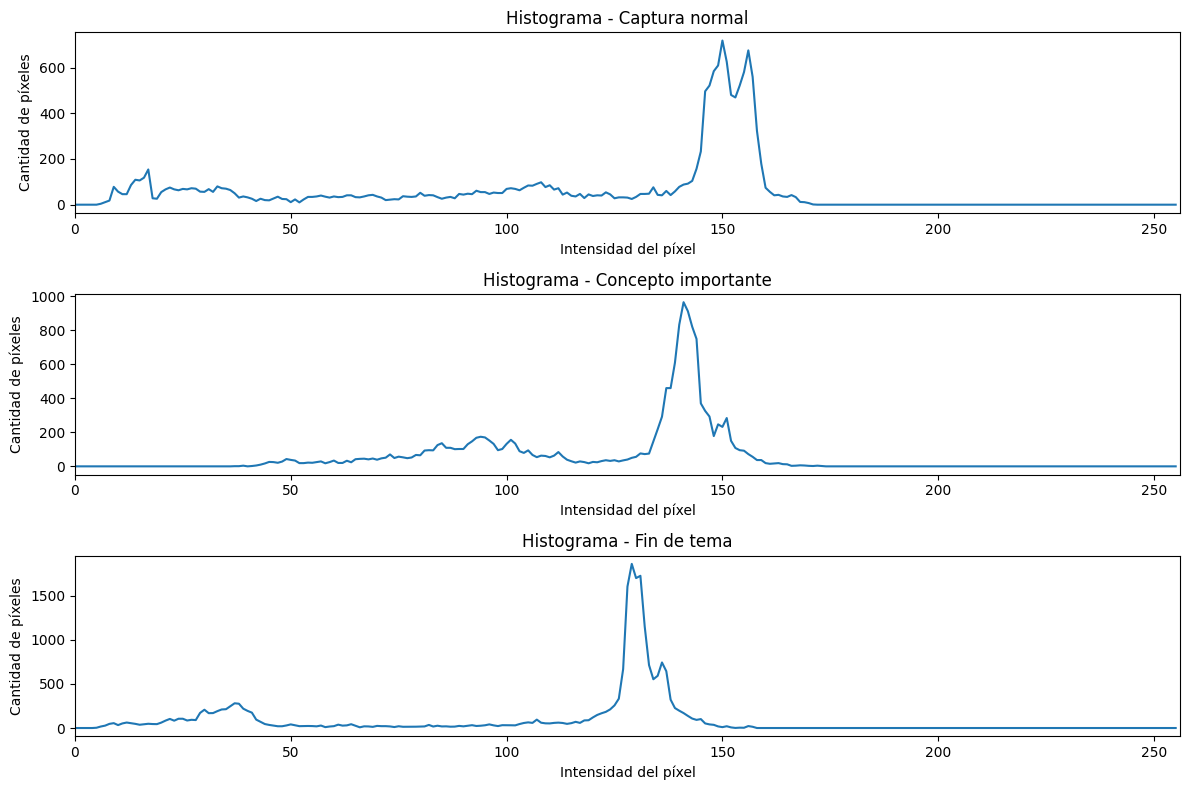

In [18]:
# Grafico los histogramas de las tres ROI para observar
# cómo se distribuyen las intensidades entre 0 (negro) y 255 (blanco).

plt.figure(figsize=(12, 8))

# Histograma de la ROI Captura normal.
plt.subplot(3, 1, 1)
plt.plot(hist_normal)
plt.title("Histograma - Captura normal")
plt.xlabel("Intensidad del píxel")
plt.ylabel("Cantidad de píxeles")
plt.xlim([0, 256])

# Histograma de la ROI Concepto importante.
plt.subplot(3, 1, 2)
plt.plot(hist_importante)
plt.title("Histograma - Concepto importante")
plt.xlabel("Intensidad del píxel")
plt.ylabel("Cantidad de píxeles")
plt.xlim([0, 256])

# Histograma de la ROI Fin de tema.
plt.subplot(3, 1, 3)
plt.plot(hist_fin)
plt.title("Histograma - Fin de tema")
plt.xlabel("Intensidad del píxel")
plt.ylabel("Cantidad de píxeles")
plt.xlim([0, 256])

plt.tight_layout()
plt.show()

In [19]:
# Normalizo los histogramas para trabajar con proporciones
# en lugar de depender de la cantidad total de píxeles de cada ROI.

hist_normal_norm = cv2.normalize(
    hist_normal,
    None,
    alpha=1,
    beta=0,
    norm_type=cv2.NORM_L1
)

hist_importante_norm = cv2.normalize(
    hist_importante,
    None,
    alpha=1,
    beta=0,
    norm_type=cv2.NORM_L1
)

hist_fin_norm = cv2.normalize(
    hist_fin,
    None,
    alpha=1,
    beta=0,
    norm_type=cv2.NORM_L1
)

# Compruebo la suma de cada histograma normalizado.
# Con NORM_L1, la suma debería quedar aproximadamente en 1.

print("Suma histograma Normal:", hist_normal_norm.sum())
print("Suma histograma Importante:", hist_importante_norm.sum())
print("Suma histograma Fin de tema:", hist_fin_norm.sum())

Suma histograma Normal: 0.99999994
Suma histograma Importante: 1.0
Suma histograma Fin de tema: 1.0


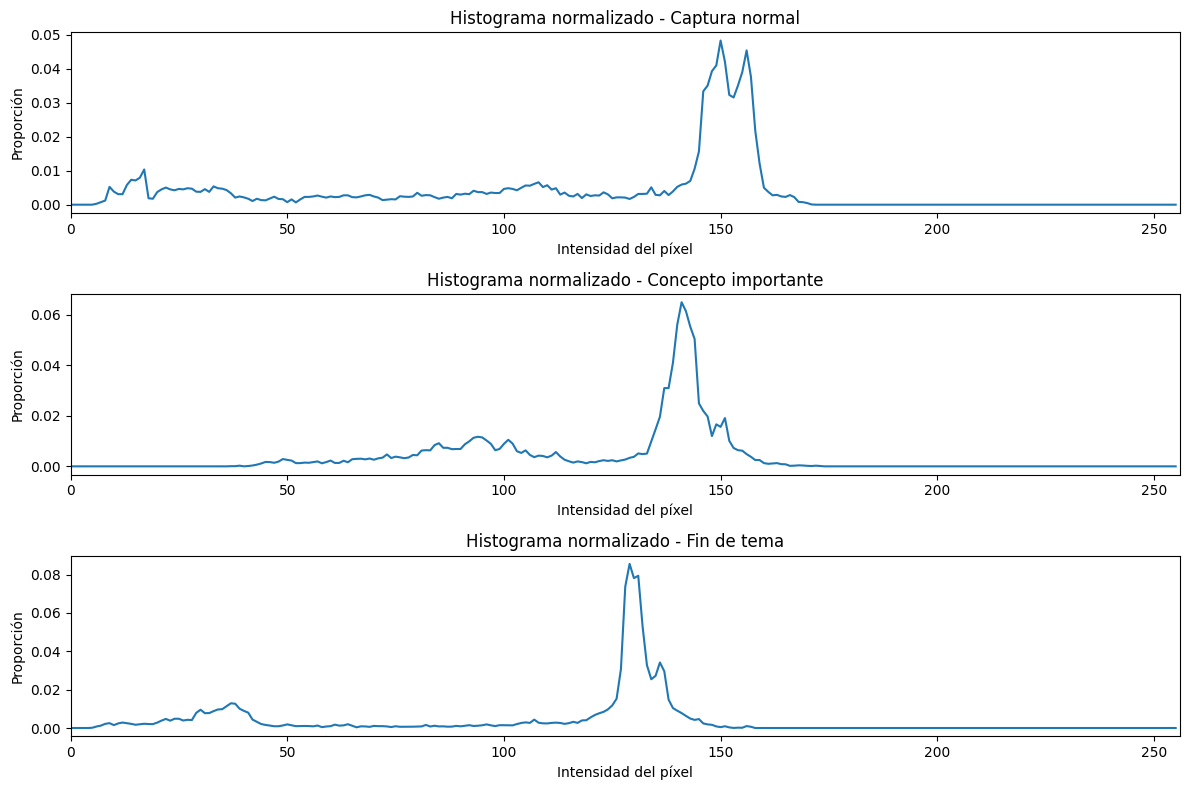

In [20]:
# Grafico los histogramas normalizados de las tres ROI.
# Ahora el eje vertical representa proporciones y no cantidades absolutas de píxeles.

plt.figure(figsize=(12, 8))

# Histograma normalizado de Captura normal.
plt.subplot(3, 1, 1)
plt.plot(hist_normal_norm)
plt.title("Histograma normalizado - Captura normal")
plt.xlabel("Intensidad del píxel")
plt.ylabel("Proporción")
plt.xlim([0, 256])

# Histograma normalizado de Concepto importante.
plt.subplot(3, 1, 2)
plt.plot(hist_importante_norm)
plt.title("Histograma normalizado - Concepto importante")
plt.xlabel("Intensidad del píxel")
plt.ylabel("Proporción")
plt.xlim([0, 256])

# Histograma normalizado de Fin de tema.
plt.subplot(3, 1, 3)
plt.plot(hist_fin_norm)
plt.title("Histograma normalizado - Fin de tema")
plt.xlabel("Intensidad del píxel")
plt.ylabel("Proporción")
plt.xlim([0, 256])

plt.tight_layout()
plt.show()

In [21]:
# Creo una función para visualizar un frame del video indicando el segundo que quiero revisar.
# Esto permitirá buscar manualmente momentos donde alguna ROI esté cubierta.

def mostrar_frame_en_segundo(segundo):

    # Calculo qué número de frame corresponde al segundo solicitado.
    numero_frame = int(segundo * fps)

    # Posiciono el video directamente en ese frame.
    video.set(cv2.CAP_PROP_POS_FRAMES, numero_frame)

    # Leo el frame seleccionado.
    ret, frame = video.read()

    # Compruebo que el frame se haya leído correctamente.
    if not ret:
        print("No se pudo leer el frame.")
        return

    # Convierto de BGR a RGB solamente para visualizar correctamente con Matplotlib.
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # Muestro el frame completo.
    plt.figure(figsize=(14, 8))
    plt.imshow(frame_rgb)
    plt.title(f"Segundo {segundo} - Frame {numero_frame}")
    plt.axis("off")
    plt.show()

In [ ]:
# Reviso un momento concreto del video para buscar una ROI cubierta.
# La función calcula automáticamente qué frame corresponde a ese segundo.

mostrar_frame_en_segundo(10)

In [ ]:
# Reviso un momento posterior del video para localizar
# una cobertura intencional de alguno de los símbolos.

mostrar_frame_en_segundo(20)

In [ ]:
# Reviso el momento aproximado en el que se cubre
# intencionalmente la ROI de Captura normal.

mostrar_frame_en_segundo(21)

In [ ]:
# Obtengo el frame correspondiente al segundo 21,
# donde la ROI de Captura normal está cubierta intencionalmente.

segundo_normal_cubierto = 21

# Calculo qué número de frame corresponde a ese momento.
numero_frame_normal_cubierto = int(segundo_normal_cubierto * fps)

# Posiciono el video en ese frame.
video.set(cv2.CAP_PROP_POS_FRAMES, numero_frame_normal_cubierto)

# Leo el frame.
ret, frame_normal_cubierto = video.read()

# Compruebo que el frame se haya leído correctamente.
if ret:

    # Recorto exactamente la misma región que definí en RF03.
    roi_normal_cubierta = frame_normal_cubierto[
        y1_normal:y2_normal,
        x1_normal:x2_normal
    ]

    # La convierto a RGB solamente para visualizarla correctamente.
    roi_normal_cubierta_rgb = cv2.cvtColor(
        roi_normal_cubierta,
        cv2.COLOR_BGR2RGB
    )

    # Muestro la ROI cubierta.
    plt.figure(figsize=(5, 4))
    plt.imshow(roi_normal_cubierta_rgb)
    plt.title("ROI Captura normal - Cubierta")
    plt.axis("off")
    plt.show()

    print("Shape ROI cubierta:", roi_normal_cubierta.shape)

else:
    print("No se pudo leer el frame.")

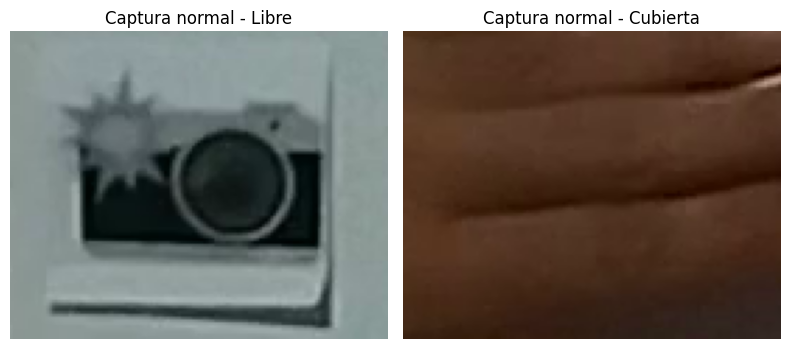

In [26]:
# Comparo visualmente la ROI de Captura normal
# en sus dos estados: libre y cubierta.

plt.figure(figsize=(8, 4))

# Muestro la ROI libre.
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(roi_normal, cv2.COLOR_BGR2RGB))
plt.title("Captura normal - Libre")
plt.axis("off")

# Muestro la misma ROI cuando está cubierta.
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(roi_normal_cubierta, cv2.COLOR_BGR2RGB))
plt.title("Captura normal - Cubierta")
plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
# Obtengo una ROI libre cercana al momento de la activación.
# Uso el segundo 20 para compararla con la ROI cubierta del segundo 21.

segundo_normal_libre = 20

# Calculo el frame correspondiente al segundo 20.
numero_frame_normal_libre = int(segundo_normal_libre * fps)

# Posiciono el video y leo ese frame.
video.set(cv2.CAP_PROP_POS_FRAMES, numero_frame_normal_libre)
ret, frame_normal_libre = video.read()

if ret:

    # Recorto exactamente la misma ROI de Captura normal.
    roi_normal_libre = frame_normal_libre[
        y1_normal:y2_normal,
        x1_normal:x2_normal
    ]

    # Convierto las dos ROI a escala de grises.
    roi_normal_libre_gris = cv2.cvtColor(
        roi_normal_libre,
        cv2.COLOR_BGR2GRAY
    )

    roi_normal_cubierta_gris = cv2.cvtColor(
        roi_normal_cubierta,
        cv2.COLOR_BGR2GRAY
    )

    # Aplico el mismo Gaussian Blur de 5x5 a los dos estados.
    roi_normal_libre_suavizada = cv2.GaussianBlur(
        roi_normal_libre_gris,
        (5, 5),
        0
    )

    roi_normal_cubierta_suavizada = cv2.GaussianBlur(
        roi_normal_cubierta_gris,
        (5, 5),
        0
    )

    # Calculo el histograma de cada estado.
    hist_normal_libre = cv2.calcHist(
        [roi_normal_libre_suavizada],
        [0],
        None,
        [256],
        [0, 256]
    )

    hist_normal_cubierta = cv2.calcHist(
        [roi_normal_cubierta_suavizada],
        [0],
        None,
        [256],
        [0, 256]
    )

    # Normalizo ambos histogramas para poder compararlos
    # utilizando proporciones y no cantidades absolutas.
    hist_normal_libre_norm = cv2.normalize(
        hist_normal_libre,
        None,
        alpha=1,
        beta=0,
        norm_type=cv2.NORM_L1
    )

    hist_normal_cubierta_norm = cv2.normalize(
        hist_normal_cubierta,
        None,
        alpha=1,
        beta=0,
        norm_type=cv2.NORM_L1
    )

    # Compruebo que ambos histogramas normalizados sumen aproximadamente 1.
    print("Suma histograma LIBRE:", hist_normal_libre_norm.sum())
    print("Suma histograma CUBIERTA:", hist_normal_cubierta_norm.sum())

else:
    print("No se pudo leer el frame libre.")

Suma histograma LIBRE: 0.99999994
Suma histograma CUBIERTA: 0.9999998


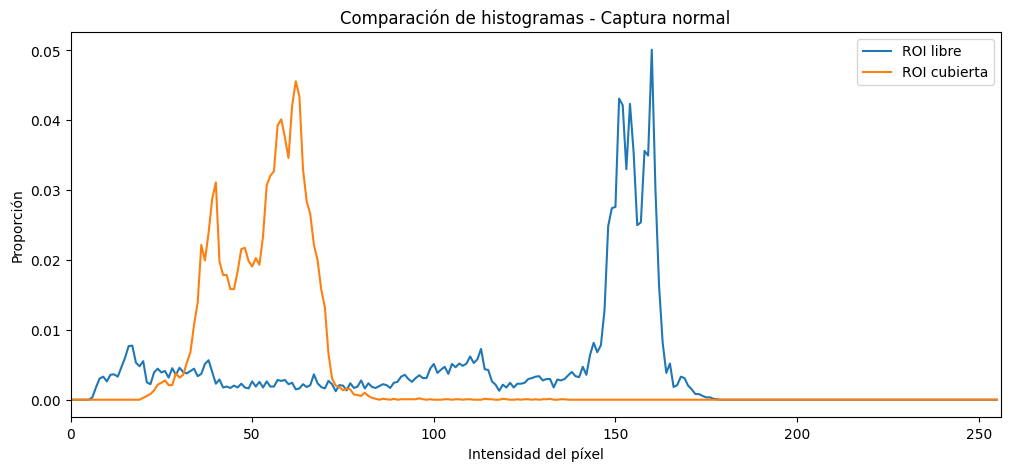

In [28]:
# Comparo en un mismo gráfico los histogramas normalizados
# de la ROI Captura normal en estado libre y cubierta.

plt.figure(figsize=(12, 5))

plt.plot(
    hist_normal_libre_norm,
    label="ROI libre"
)

plt.plot(
    hist_normal_cubierta_norm,
    label="ROI cubierta"
)

plt.title("Comparación de histogramas - Captura normal")
plt.xlabel("Intensidad del píxel")
plt.ylabel("Proporción")
plt.xlim([0, 256])

# Agrego una leyenda para distinguir ambos estados.
plt.legend()

plt.show()

## 🔎 RF05 — Detección de cambios

Hasta este punto se comprobó visualmente que el histograma de una ROI cambia cuando el símbolo es cubierto.

El siguiente objetivo es transformar esa diferencia visual en un **valor numérico**, para que el sistema pueda detectar el cambio automáticamente sin necesidad de observar los gráficos.

Para comparar histogramas se utilizará inicialmente la **distancia de Bhattacharyya**, disponible en OpenCV.

Su interpretación es sencilla:

```text
Valor cercano a 0 → histogramas muy similares

Valor que aumenta hacia 1 → histogramas cada vez más diferentes
```

Por ejemplo:

```text
0.05 → muy similares
0.20 → cierta diferencia
0.60 → diferencia importante
0.90 → muy diferentes
```

Estos valores son solamente orientativos.

En Pizarra Snap todavía no se definirá un valor fijo como límite. Primero se medirán distintos casos reales del video y luego se establecerá experimentalmente un **umbral de detección** que permita diferenciar una ROI libre de una ROI cubierta.

In [29]:
# Comparo el histograma de la ROI libre con el histograma
# de la misma ROI cuando está cubierta.

# Convierto los histogramas a float32 para asegurar
# el formato esperado por OpenCV al realizar la comparación.

hist_normal_libre_comparar = hist_normal_libre_norm.astype(np.float32)
hist_normal_cubierta_comparar = hist_normal_cubierta_norm.astype(np.float32)

# Calculo la distancia de Bhattacharyya entre ambos histogramas.
# Un valor cercano a 0 indica similitud.
# Un valor que aumenta hacia 1 indica mayor diferencia.

distancia_normal = cv2.compareHist(
    hist_normal_libre_comparar,
    hist_normal_cubierta_comparar,
    cv2.HISTCMP_BHATTACHARYYA
)

# Muestro el resultado obtenido.

print(
    "Distancia Bhattacharyya - Captura normal LIBRE vs CUBIERTA:",
    distancia_normal
)

Distancia Bhattacharyya - Captura normal LIBRE vs CUBIERTA: 0.796669416916033


In [30]:
# Obtengo otro momento donde la ROI de Captura normal está libre.
# Uso el segundo 19 para compararlo con el segundo 20.

segundo_normal_libre_2 = 19

# Calculo el frame correspondiente.
numero_frame_normal_libre_2 = int(segundo_normal_libre_2 * fps)

# Posiciono el video y leo ese frame.
video.set(cv2.CAP_PROP_POS_FRAMES, numero_frame_normal_libre_2)
ret, frame_normal_libre_2 = video.read()

if ret:

    # Recorto exactamente la misma ROI.
    roi_normal_libre_2 = frame_normal_libre_2[
        y1_normal:y2_normal,
        x1_normal:x2_normal
    ]

    # Convierto la ROI a escala de grises.
    roi_normal_libre_2_gris = cv2.cvtColor(
        roi_normal_libre_2,
        cv2.COLOR_BGR2GRAY
    )

    # Aplico el mismo Gaussian Blur de 5x5.
    roi_normal_libre_2_suavizada = cv2.GaussianBlur(
        roi_normal_libre_2_gris,
        (5, 5),
        0
    )

    # Calculo su histograma.
    hist_normal_libre_2 = cv2.calcHist(
        [roi_normal_libre_2_suavizada],
        [0],
        None,
        [256],
        [0, 256]
    )

    # Normalizo el histograma.
    hist_normal_libre_2_norm = cv2.normalize(
        hist_normal_libre_2,
        None,
        alpha=1,
        beta=0,
        norm_type=cv2.NORM_L1
    )

    # Comparo segundo 20 contra segundo 19.
    distancia_normal_libre_libre = cv2.compareHist(
        hist_normal_libre_norm.astype(np.float32),
        hist_normal_libre_2_norm.astype(np.float32),
        cv2.HISTCMP_BHATTACHARYYA
    )

    print(
        "Distancia Bhattacharyya - Captura normal LIBRE vs LIBRE:",
        distancia_normal_libre_libre
    )

else:
    print("No se pudo leer el segundo frame libre.")

Distancia Bhattacharyya - Captura normal LIBRE vs LIBRE: 0.1116653678598884


In [31]:
# Creo una función que prepara una ROI y devuelve
# su histograma normalizado listo para comparar.

def calcular_histograma_roi(roi):

    # Convierto la ROI de BGR a escala de grises.
    roi_gris = cv2.cvtColor(
        roi,
        cv2.COLOR_BGR2GRAY
    )

    # Aplico el mismo suavizado Gaussiano utilizado anteriormente.
    roi_suavizada = cv2.GaussianBlur(
        roi_gris,
        (5, 5),
        0
    )

    # Calculo el histograma de intensidades de 0 a 255.
    histograma = cv2.calcHist(
        [roi_suavizada],
        [0],
        None,
        [256],
        [0, 256]
    )

    # Normalizo el histograma para trabajar con proporciones.
    histograma_normalizado = cv2.normalize(
        histograma,
        None,
        alpha=1,
        beta=0,
        norm_type=cv2.NORM_L1
    )

    # Devuelvo el histograma en formato float32,
    # listo para utilizar con cv2.compareHist().
    return histograma_normalizado.astype(np.float32)

In [32]:
# Creo una función para obtener una ROI directamente
# indicando el segundo del video y sus coordenadas.

def obtener_roi_en_segundo(segundo, x1, x2, y1, y2):

    # Calculo qué número de frame corresponde al segundo indicado.
    numero_frame = int(segundo * fps)

    # Posiciono el video directamente en ese frame.
    video.set(cv2.CAP_PROP_POS_FRAMES, numero_frame)

    # Leo el frame seleccionado.
    ret, frame = video.read()

    # Si el frame no pudo leerse, devuelvo None.
    if not ret:
        print(f"No se pudo leer el frame del segundo {segundo}.")
        return None

    # Recorto la región de interés usando las coordenadas recibidas.
    roi = frame[
        y1:y2,
        x1:x2
    ]

    # Devuelvo la ROI obtenida.
    return roi

In [33]:
# Tomo como referencia la ROI de Captura normal del segundo 20,
# donde el símbolo se encuentra visible y libre.

roi_referencia_normal = obtener_roi_en_segundo(
    20,
    x1_normal,
    x2_normal,
    y1_normal,
    y2_normal
)

# Calculo una sola vez el histograma de referencia.
hist_referencia_normal = calcular_histograma_roi(
    roi_referencia_normal
)

# Defino distintos momentos del video para comparar.
segundos_prueba_normal = [
    18,
    19,
    19.5,
    20,
    21
]

# Recorro cada momento y comparo su histograma
# contra el histograma de referencia del segundo 20.

for segundo in segundos_prueba_normal:

    # Obtengo la misma ROI en el segundo que estoy evaluando.
    roi_prueba = obtener_roi_en_segundo(
        segundo,
        x1_normal,
        x2_normal,
        y1_normal,
        y2_normal
    )

    # Si la ROI se obtuvo correctamente, continúo.
    if roi_prueba is not None:

        # Preparo su histograma utilizando la función creada anteriormente.
        hist_prueba = calcular_histograma_roi(
            roi_prueba
        )

        # Calculo la distancia de Bhattacharyya
        # respecto del estado libre de referencia.
        distancia = cv2.compareHist(
            hist_referencia_normal,
            hist_prueba,
            cv2.HISTCMP_BHATTACHARYYA
        )

        # Muestro el segundo analizado y la distancia obtenida.
        print(
            f"Segundo {segundo:>4} → Distancia: {distancia:.4f}"
        )

Segundo   18 → Distancia: 0.1263
Segundo   19 → Distancia: 0.1117
Segundo 19.5 → Distancia: 0.0901
Segundo   20 → Distancia: 0.0000
Segundo   21 → Distancia: 0.7967


In [34]:
# Analizo varios momentos alrededor de la activación de Captura normal.
# Esto permite observar cómo cambia la distancia mientras la mano
# comienza a cubrir la ROI.

segundos_evento_normal = [
    20.0,
    20.2,
    20.4,
    20.6,
    20.8,
    21.0,
    21.2,
    21.4,
    21.6,
    21.8,
    22.0
]

# Recorro cada momento y lo comparo contra
# el estado libre de referencia del segundo 20.

for segundo in segundos_evento_normal:

    # Obtengo la ROI de Captura normal en ese momento.
    roi_prueba = obtener_roi_en_segundo(
        segundo,
        x1_normal,
        x2_normal,
        y1_normal,
        y2_normal
    )

    # Continúo solamente si pude obtener correctamente la ROI.
    if roi_prueba is not None:

        # Calculo su histograma normalizado.
        hist_prueba = calcular_histograma_roi(
            roi_prueba
        )

        # Comparo contra el histograma libre de referencia.
        distancia = cv2.compareHist(
            hist_referencia_normal,
            hist_prueba,
            cv2.HISTCMP_BHATTACHARYYA
        )

        # Muestro el segundo y la distancia obtenida.
        print(
            f"Segundo {segundo:>4.1f} → Distancia: {distancia:.4f}"
        )

Segundo 20.0 → Distancia: 0.0000
Segundo 20.2 → Distancia: 0.0665
Segundo 20.4 → Distancia: 0.0953
Segundo 20.6 → Distancia: 0.1258
Segundo 20.8 → Distancia: 0.2544
Segundo 21.0 → Distancia: 0.7967
Segundo 21.2 → Distancia: 0.8085
Segundo 21.4 → Distancia: 0.7981
Segundo 21.6 → Distancia: 0.7974
Segundo 21.8 → Distancia: 0.7952
Segundo 22.0 → Distancia: 0.7957


In [35]:
# Continúo analizando el evento después del segundo 22
# para observar cuándo la ROI vuelve a quedar libre.

segundos_salida_normal = [
    22.0,
    22.2,
    22.4,
    22.6,
    22.8,
    23.0,
    23.2,
    23.4,
    23.6,
    23.8,
    24.0
]

# Comparo nuevamente cada momento contra
# el estado libre de referencia del segundo 20.

for segundo in segundos_salida_normal:

    # Obtengo la misma ROI en el momento que estoy evaluando.
    roi_prueba = obtener_roi_en_segundo(
        segundo,
        x1_normal,
        x2_normal,
        y1_normal,
        y2_normal
    )

    if roi_prueba is not None:

        # Calculo el histograma de la ROI.
        hist_prueba = calcular_histograma_roi(
            roi_prueba
        )

        # Mido cuánto se diferencia de la referencia libre.
        distancia = cv2.compareHist(
            hist_referencia_normal,
            hist_prueba,
            cv2.HISTCMP_BHATTACHARYYA
        )

        # Muestro el resultado.
        print(
            f"Segundo {segundo:>4.1f} → Distancia: {distancia:.4f}"
        )

Segundo 22.0 → Distancia: 0.7957
Segundo 22.2 → Distancia: 0.7964
Segundo 22.4 → Distancia: 0.7957
Segundo 22.6 → Distancia: 0.7946
Segundo 22.8 → Distancia: 0.3844
Segundo 23.0 → Distancia: 0.2203
Segundo 23.2 → Distancia: 0.1849
Segundo 23.4 → Distancia: 0.1758
Segundo 23.6 → Distancia: 0.1727
Segundo 23.8 → Distancia: 0.1553
Segundo 24.0 → Distancia: 0.1172


In [36]:
# Creo una función para medir cuánto cambió una ROI
# respecto de un histograma tomado como referencia.

def medir_distancia_roi(
    segundo,
    x1,
    x2,
    y1,
    y2,
    histograma_referencia
):

    # Obtengo la ROI correspondiente al segundo indicado.
    roi_actual = obtener_roi_en_segundo(
        segundo,
        x1,
        x2,
        y1,
        y2
    )

    # Si no pude obtener la ROI, no continúo con la comparación.
    if roi_actual is None:
        return None

    # Calculo el histograma normalizado de la ROI actual.
    histograma_actual = calcular_histograma_roi(
        roi_actual
    )

    # Comparo el histograma actual con el de referencia.
    distancia = cv2.compareHist(
        histograma_referencia,
        histograma_actual,
        cv2.HISTCMP_BHATTACHARYYA
    )

    # Devuelvo el valor de distancia obtenido.
    return distancia

Según lo que observe en el video, la estrella (⭐ Concepto importante), se cubre aproximadamente entre los 35 y 36 segundos. Primero hay que localizar un frame limpio de esa acción.

In [ ]:
# Reviso el momento aproximado en el que cubro
# intencionalmente la ROI de Concepto importante.

mostrar_frame_en_segundo(35.8)

In [ ]:
# Avanzo unas décimas de segundo para buscar
# el momento en que la estrella ya está siendo cubierta.

mostrar_frame_en_segundo(36.2)

In [ ]:
# Avanzo dos décimas de segundo para seguir buscando
# el momento en que la estrella queda claramente cubierta.

mostrar_frame_en_segundo(36.4)

In [40]:
# Tomo una referencia libre de la ROI de Concepto importante.
# Uso el segundo 35.8 porque la estrella todavía está visible.

roi_referencia_importante = obtener_roi_en_segundo(
    35.8,
    x1_importante,
    x2_importante,
    y1_importante,
    y2_importante
)

# Calculo el histograma de referencia.
hist_referencia_importante = calcular_histograma_roi(
    roi_referencia_importante
)

# Mido cuánto cambia la misma ROI en el segundo 36.4,
# donde ya aparece la mano sobre la estrella.

distancia_importante_36_4 = medir_distancia_roi(
    36.4,
    x1_importante,
    x2_importante,
    y1_importante,
    y2_importante,
    hist_referencia_importante
)

print(
    "Distancia Bhattacharyya - Concepto importante (35.8 vs 36.4):",
    distancia_importante_36_4
)

Distancia Bhattacharyya - Concepto importante (35.8 vs 36.4): 0.846089097770536


In [41]:
# Comparo dos momentos donde la ROI de Concepto importante
# debería encontrarse libre y visible.

distancia_importante_libre_libre = medir_distancia_roi(
    35.4,
    x1_importante,
    x2_importante,
    y1_importante,
    y2_importante,
    hist_referencia_importante
)

print(
    "Distancia Bhattacharyya - Concepto importante LIBRE vs LIBRE:",
    distancia_importante_libre_libre
)

Distancia Bhattacharyya - Concepto importante LIBRE vs LIBRE: 0.06224758487912381


Siguiente paso: localizar 📌 Fin de tema

Segundo 48. Primero miro ese momento, igual que lo hice con la estrella.

In [ ]:
# Reviso el momento aproximado en el que cubro
# intencionalmente la ROI de Fin de tema.

mostrar_frame_en_segundo(48.0)

In [ ]:
# Avanzo unas décimas de segundo para buscar
# el inicio de la cobertura de la ROI Fin de tema.

mostrar_frame_en_segundo(48.4)

In [ ]:
# Avanzo unas décimas de segundo para seguir buscando
# el momento en que comienza la cobertura de la ROI Fin de tema.

mostrar_frame_en_segundo(48.8)

In [ ]:
# Avanzo unas décimas más para localizar
# el momento en que comienza la cobertura de Fin de tema.

mostrar_frame_en_segundo(49.2)

In [ ]:
# Reviso el punto intermedio entre 48.8 y 49.2 segundos
# para localizar con mayor precisión el inicio de la activación.

mostrar_frame_en_segundo(49.0)

In [ ]:
# Reviso un punto intermedio entre 49.0 y 49.2 segundos
# para localizar con mayor precisión el comienzo de la cobertura.

mostrar_frame_en_segundo(49.1)


In [48]:
# Tomo como referencia la ROI Fin de tema del segundo 49.0,
# donde el símbolo todavía se encuentra completamente libre.

roi_referencia_fin = obtener_roi_en_segundo(
    49.0,
    x1_fin,
    x2_fin,
    y1_fin,
    y2_fin
)

# Calculo el histograma normalizado de la referencia libre.
hist_referencia_fin = calcular_histograma_roi(
    roi_referencia_fin
)

# Mido cuánto cambió la ROI apenas comienza a entrar la mano,
# en el segundo 49.1.

distancia_fin_49_1 = medir_distancia_roi(
    49.1,
    x1_fin,
    x2_fin,
    y1_fin,
    y2_fin,
    hist_referencia_fin
)

print(
    "Distancia Bhattacharyya - Fin de tema (49.0 vs 49.1):",
    distancia_fin_49_1
)

Distancia Bhattacharyya - Fin de tema (49.0 vs 49.1): 0.14833531441532577


In [49]:
# Mido cuánto cambió la ROI Fin de tema en el segundo 49.2,
# donde la mano ya ocupa una parte mayor de la región.

distancia_fin_49_2 = medir_distancia_roi(
    49.2,
    x1_fin,
    x2_fin,
    y1_fin,
    y2_fin,
    hist_referencia_fin
)

print(
    "Distancia Bhattacharyya - Fin de tema (49.0 vs 49.2):",
    distancia_fin_49_2
)

Distancia Bhattacharyya - Fin de tema (49.0 vs 49.2): 0.5488189817439715


In [50]:
# Comparo dos momentos donde la ROI Fin de tema
# debería encontrarse libre y visible.

distancia_fin_libre_libre = medir_distancia_roi(
    48.8,
    x1_fin,
    x2_fin,
    y1_fin,
    y2_fin,
    hist_referencia_fin
)

print(
    "Distancia Bhattacharyya - Fin de tema LIBRE vs LIBRE:",
    distancia_fin_libre_libre
)

Distancia Bhattacharyya - Fin de tema LIBRE vs LIBRE: 0.08242370565601152


In [51]:
# Pruebo un momento del video donde hay movimiento cerca de las ROI,
# pero no se está realizando intencionalmente el comando Captura normal.
# Esta prueba ayuda a estudiar posibles falsos positivos.

roi_referencia_prueba_normal = obtener_roi_en_segundo(
    20.0,
    x1_normal,
    x2_normal,
    y1_normal,
    y2_normal
)

# Calculo el histograma de referencia con la ROI libre.
hist_referencia_prueba_normal = calcular_histograma_roi(
    roi_referencia_prueba_normal
)

# Mido la diferencia respecto del segundo 10,
# donde hay una persona trabajando cerca de la zona izquierda.

distancia_movimiento_normal = medir_distancia_roi(
    10.0,
    x1_normal,
    x2_normal,
    y1_normal,
    y2_normal,
    hist_referencia_prueba_normal
)

print(
    "Distancia Bhattacharyya - Movimiento cercano sin activación:",
    distancia_movimiento_normal
)

Distancia Bhattacharyya - Movimiento cercano sin activación: 0.8812829394441414


In [52]:
# Realizo una prueba de movimiento cercano sin cubrir la ROI de Captura normal.
# Comparo dos momentos muy próximos para reducir diferencias de iluminación.

# Tomo la ROI de Captura normal en el segundo 35.8 como referencia libre.
roi_referencia_normal_movimiento = obtener_roi_en_segundo(
    35.8,
    x1_normal,
    x2_normal,
    y1_normal,
    y2_normal
)

# Calculo su histograma de referencia.
hist_referencia_normal_movimiento = calcular_histograma_roi(
    roi_referencia_normal_movimiento
)

# Comparo contra el segundo 36.2.
# En este momento hay movimiento de la mano cerca del lateral,
# pero la ROI de Captura normal continúa visible.

distancia_movimiento_cercano_normal = medir_distancia_roi(
    36.2,
    x1_normal,
    x2_normal,
    y1_normal,
    y2_normal,
    hist_referencia_normal_movimiento
)

print(
    "Distancia - Movimiento cercano con ROI Normal visible:",
    distancia_movimiento_cercano_normal
)

Distancia - Movimiento cercano con ROI Normal visible: 0.17671242885660066


In [53]:
# Defino un primer umbral experimental para detectar cambios importantes.
# Este valor es provisional y podrá ajustarse después de realizar más pruebas.

umbral_cobertura = 0.40


# Creo una función que interpreta la distancia obtenida
# y devuelve el estado visual de la ROI.

def clasificar_estado_roi(distancia, umbral=umbral_cobertura):

    # Si la distancia supera el umbral,
    # considero que hubo un cambio visual suficientemente grande.
    if distancia >= umbral:
        return "CUBIERTA"

    # Si no supera el umbral,
    # considero que la ROI continúa libre.
    return "LIBRE"


# Compruebo la lógica utilizando algunos resultados reales obtenidos.

print("Captura normal libre:",
      clasificar_estado_roi(0.1117))

print("Movimiento cercano:",
      clasificar_estado_roi(0.1767))

print("Captura normal cubierta:",
      clasificar_estado_roi(0.7967))

print("Concepto importante cubierto:",
      clasificar_estado_roi(0.8461))

print("Fin de tema con mayor cobertura:",
      clasificar_estado_roi(0.5488))

Captura normal libre: LIBRE
Movimiento cercano: LIBRE
Captura normal cubierta: CUBIERTA
Concepto importante cubierto: CUBIERTA
Fin de tema con mayor cobertura: CUBIERTA


In [54]:
# Creo una función que integra la medición de distancia
# y la clasificación final del estado de una ROI.

def detectar_estado_roi(
    segundo,
    x1,
    x2,
    y1,
    y2,
    histograma_referencia,
    umbral=umbral_cobertura
):

    # Mido cuánto cambió la ROI respecto de su estado de referencia.
    distancia = medir_distancia_roi(
        segundo,
        x1,
        x2,
        y1,
        y2,
        histograma_referencia
    )

    # Si no pude calcular la distancia, no continúo.
    if distancia is None:
        return None, "ERROR"

    # Clasifico la ROI como LIBRE o CUBIERTA
    # utilizando el umbral experimental definido.
    estado = clasificar_estado_roi(
        distancia,
        umbral
    )

    # Devuelvo tanto la distancia como el estado.
    return distancia, estado

In [55]:
# Pruebo la función final de detección con las tres ROI
# utilizando momentos reales del video donde los comandos están cubiertos.

# 📸 Captura normal - cubierta alrededor del segundo 21.
distancia_normal_final, estado_normal_final = detectar_estado_roi(
    21.0,
    x1_normal,
    x2_normal,
    y1_normal,
    y2_normal,
    hist_referencia_normal
)

# ⭐ Concepto importante - cubierta alrededor del segundo 36.4.
distancia_importante_final, estado_importante_final = detectar_estado_roi(
    36.4,
    x1_importante,
    x2_importante,
    y1_importante,
    y2_importante,
    hist_referencia_importante
)

# 📌 Fin de tema - con cobertura suficiente alrededor del segundo 49.2.
distancia_fin_final, estado_fin_final = detectar_estado_roi(
    49.2,
    x1_fin,
    x2_fin,
    y1_fin,
    y2_fin,
    hist_referencia_fin
)

# Muestro los resultados de manera clara.

print(
    f"📸 Captura normal      → Distancia: {distancia_normal_final:.4f} | Estado: {estado_normal_final}"
)

print(
    f"⭐ Concepto importante → Distancia: {distancia_importante_final:.4f} | Estado: {estado_importante_final}"
)

print(
    f"📌 Fin de tema         → Distancia: {distancia_fin_final:.4f} | Estado: {estado_fin_final}"
)

📸 Captura normal      → Distancia: 0.7967 | Estado: CUBIERTA
⭐ Concepto importante → Distancia: 0.8461 | Estado: CUBIERTA
📌 Fin de tema         → Distancia: 0.5488 | Estado: CUBIERTA


In [56]:
# Pruebo la función final con las tres ROI en momentos
# donde los símbolos se encuentran visibles y libres.

# 📸 Captura normal - libre en el segundo 20.
distancia_normal_libre_final, estado_normal_libre_final = detectar_estado_roi(
    20.0,
    x1_normal,
    x2_normal,
    y1_normal,
    y2_normal,
    hist_referencia_normal
)

# ⭐ Concepto importante - libre en el segundo 35.8.
distancia_importante_libre_final, estado_importante_libre_final = detectar_estado_roi(
    35.8,
    x1_importante,
    x2_importante,
    y1_importante,
    y2_importante,
    hist_referencia_importante
)

# 📌 Fin de tema - libre en el segundo 49.0.
distancia_fin_libre_final, estado_fin_libre_final = detectar_estado_roi(
    49.0,
    x1_fin,
    x2_fin,
    y1_fin,
    y2_fin,
    hist_referencia_fin
)

# Muestro los resultados.

print(
    f"📸 Captura normal      → Distancia: {distancia_normal_libre_final:.4f} | Estado: {estado_normal_libre_final}"
)

print(
    f"⭐ Concepto importante → Distancia: {distancia_importante_libre_final:.4f} | Estado: {estado_importante_libre_final}"
)

print(
    f"📌 Fin de tema         → Distancia: {distancia_fin_libre_final:.4f} | Estado: {estado_fin_libre_final}"
)

📸 Captura normal      → Distancia: 0.0000 | Estado: LIBRE
⭐ Concepto importante → Distancia: 0.0000 | Estado: LIBRE
📌 Fin de tema         → Distancia: 0.0000 | Estado: LIBRE


In [57]:
# Realizo una prueba más exigente utilizando momentos libres
# distintos de los frames usados como referencia.

# 📸 Captura normal:
# la referencia es el segundo 20 y pruebo contra el segundo 19.
distancia_normal_libre_real, estado_normal_libre_real = detectar_estado_roi(
    19.0,
    x1_normal,
    x2_normal,
    y1_normal,
    y2_normal,
    hist_referencia_normal
)

# ⭐ Concepto importante:
# la referencia es el segundo 35.8 y pruebo contra el segundo 35.4.
distancia_importante_libre_real, estado_importante_libre_real = detectar_estado_roi(
    35.4,
    x1_importante,
    x2_importante,
    y1_importante,
    y2_importante,
    hist_referencia_importante
)

# 📌 Fin de tema:
# la referencia es el segundo 49.0 y pruebo contra el segundo 48.8.
distancia_fin_libre_real, estado_fin_libre_real = detectar_estado_roi(
    48.8,
    x1_fin,
    x2_fin,
    y1_fin,
    y2_fin,
    hist_referencia_fin
)

# Muestro los resultados obtenidos.

print(
    f"📸 Captura normal      → Distancia: {distancia_normal_libre_real:.4f} | Estado: {estado_normal_libre_real}"
)

print(
    f"⭐ Concepto importante → Distancia: {distancia_importante_libre_real:.4f} | Estado: {estado_importante_libre_real}"
)

print(
    f"📌 Fin de tema         → Distancia: {distancia_fin_libre_real:.4f} | Estado: {estado_fin_libre_real}"
)

📸 Captura normal      → Distancia: 0.1117 | Estado: LIBRE
⭐ Concepto importante → Distancia: 0.0622 | Estado: LIBRE
📌 Fin de tema         → Distancia: 0.0824 | Estado: LIBRE


In [58]:
# Pruebo momentos de transición, donde la mano recién comienza
# a acercarse o entrar en las ROI.

# 📸 Captura normal - comienzo de la cobertura.
distancia_normal_transicion, estado_normal_transicion = detectar_estado_roi(
    20.8,
    x1_normal,
    x2_normal,
    y1_normal,
    y2_normal,
    hist_referencia_normal
)

# ⭐ Concepto importante - movimiento cercano antes
# de la cobertura clara de la estrella.
distancia_importante_transicion, estado_importante_transicion = detectar_estado_roi(
    36.2,
    x1_importante,
    x2_importante,
    y1_importante,
    y2_importante,
    hist_referencia_importante
)

# 📌 Fin de tema - la mano recién empieza a entrar.
distancia_fin_transicion, estado_fin_transicion = detectar_estado_roi(
    49.1,
    x1_fin,
    x2_fin,
    y1_fin,
    y2_fin,
    hist_referencia_fin
)

# Muestro los resultados.

print(
    f"📸 Captura normal      → Distancia: {distancia_normal_transicion:.4f} | Estado: {estado_normal_transicion}"
)

print(
    f"⭐ Concepto importante → Distancia: {distancia_importante_transicion:.4f} | Estado: {estado_importante_transicion}"
)

print(
    f"📌 Fin de tema         → Distancia: {distancia_fin_transicion:.4f} | Estado: {estado_fin_transicion}"
)

📸 Captura normal      → Distancia: 0.2544 | Estado: LIBRE
⭐ Concepto importante → Distancia: 0.1747 | Estado: LIBRE
📌 Fin de tema         → Distancia: 0.1483 | Estado: LIBRE


## ✅ Resultados de RF05 — Detección de cambios

Luego de preparar las ROI mediante escala de grises, Gaussian Blur, cálculo de histogramas y normalización, se utilizó la **distancia de Bhattacharyya** para medir cuantitativamente cuánto cambia cada región respecto de un estado libre de referencia.

### Resultados obtenidos

Se realizaron pruebas con las tres regiones de interés utilizando momentos reales del video.

| ROI | Libre vs libre | Transición | Cobertura clara |
|---|---:|---:|---:|
| 📸 Captura normal | 0.1117 | 0.2544 | 0.7967 |
| ⭐ Concepto importante | 0.0622 | 0.1747 | 0.8461 |
| 📌 Fin de tema | 0.0824 | 0.1483 | 0.5488 |

También se realizó una prueba con movimiento cercano a la ROI de Captura normal sin cubrirla, obteniendo una distancia aproximada de:

```text
0.1767
```

Este valor continuó dentro del rango considerado como estado libre.

### Umbral experimental

A partir de las mediciones realizadas se estableció inicialmente:

```python
umbral_cobertura = 0.40
```

La decisión utilizada es:

```text
distancia < 0.40  → LIBRE
distancia >= 0.40 → CUBIERTA
```

El valor `0.40` es un **umbral experimental**, obtenido a partir del video de prueba actual.

No debe considerarse un valor universal o definitivo y podrá requerir calibración si cambian las condiciones de cámara, iluminación, pizarra o tamaño de las ROI.

### Comportamiento observado

Los resultados muestran tres zonas de comportamiento claramente diferenciadas:

```text
ROI LIBRE
distancias bajas

        ↓

TRANSICIÓN
la mano comienza a entrar,
pero todavía no existe una cobertura suficiente

        ↓

ROI CUBIERTA
distancias claramente mayores
```

El detector respondió correctamente en las pruebas realizadas:

- las ROI libres fueron clasificadas como `LIBRE`;
- el movimiento cercano sin cubrir la zona permaneció como `LIBRE`;
- las coberturas claras fueron clasificadas como `CUBIERTA`;
- las entradas parciales iniciales de la mano permanecieron por debajo del umbral.

### Limitación conocida

RF05 detecta **cambios visuales importantes**, pero todavía no determina si una cobertura fue intencional.

Por ejemplo, si una persona tapa accidentalmente por completo una ROI, el cambio puede ser suficientemente grande como para clasificarla como `CUBIERTA`.

La validación de una acción completa:

```text
VISIBLE → CUBIERTA → VISIBLE
```

y el control de eventos accidentales o duplicados corresponden a los requerimientos posteriores del proyecto.

### Salida de RF05

El módulo deja disponibles funciones capaces de:

1. obtener una ROI desde un momento determinado del video;
2. procesarla en escala de grises;
3. aplicar Gaussian Blur;
4. calcular y normalizar su histograma;
5. compararlo con un histograma de referencia;
6. obtener una distancia de Bhattacharyya;
7. clasificar finalmente la región como:

```text
LIBRE
o
CUBIERTA
```

Esta salida queda preparada para que el siguiente módulo pueda identificar qué zona visual fue activada.

In [59]:
# Realizo una prueba final de aceptación de RF05.
# Compruebo automáticamente que los estados libres y cubiertos
# hayan sido clasificados correctamente.

# Casos que deberían quedar LIBRES.
assert estado_normal_libre_real == "LIBRE"
assert estado_importante_libre_real == "LIBRE"
assert estado_fin_libre_real == "LIBRE"

# Casos de transición que todavía deberían quedar LIBRES.
assert estado_normal_transicion == "LIBRE"
assert estado_importante_transicion == "LIBRE"
assert estado_fin_transicion == "LIBRE"

# Casos con cobertura clara que deberían quedar CUBIERTOS.
assert estado_normal_final == "CUBIERTA"
assert estado_importante_final == "CUBIERTA"
assert estado_fin_final == "CUBIERTA"

# Si todas las comprobaciones anteriores se cumplen,
# muestro un mensaje final de validación.

print("✅ RF05 validado correctamente.")
print("Las tres ROI distinguen estados LIBRE y CUBIERTA con el umbral experimental.")

✅ RF05 validado correctamente.
Las tres ROI distinguen estados LIBRE y CUBIERTA con el umbral experimental.
